# Module 08, Part 3: Conditional GANs and image-to-image translation

This notebook is the runnable companion to Part 3 of the Module 08 learning content. It checks, with code:

1. Whether a GAN given a label as an extra input produces the requested digit, and whether the label controls the class while the noise controls everything else.
2. What a paired image-to-image model learns when the task has more than one right answer, with the task "given the top half of a digit, draw the bottom half".
3. What the adversarial term changes in that task, compared with plain regression under a squared-error loss and under an L1 loss.

The conditional GAN uses the WGAN-GP setup of Part 2 (three seeds, about eight minutes in all). The translation models train in seconds.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(d_in, d_out, d_hidden=64, layers=2, act=nn.ReLU, spectral=False):
    mods, d = [], d_in
    for _ in range(layers):
        lin = nn.Linear(d, d_hidden)
        mods += [nn.utils.spectral_norm(lin) if spectral else lin, act()]
        d = d_hidden
    last = nn.Linear(d, d_out)
    mods.append(nn.utils.spectral_norm(last) if spectral else last)
    return nn.Sequential(*mods)


class Generator(nn.Module):
    """Maps noise (and an optional one-hot label) to a sample. out_act='sigmoid' for images in [0, 1], None for raw coordinates."""

    def __init__(self, d_noise=8, d_out=2, d_hidden=64, n_classes=0, out_act=None):
        super().__init__()
        self.d_noise, self.n_classes = d_noise, n_classes
        self.net = mlp(d_noise + n_classes, d_out, d_hidden)
        self.out_act = out_act

    def forward(self, z, c=None):
        out = self.net(z if c is None else torch.cat([z, c], 1))
        return torch.sigmoid(out) if self.out_act == "sigmoid" else out


class Discriminator(nn.Module):
    """Returns a logit (a real-valued score for the Wasserstein critic). With n_classes > 0 it also sees the label."""

    def __init__(self, d_in=2, d_hidden=64, n_classes=0, spectral=False):
        super().__init__()
        self.net = mlp(d_in + n_classes, 1, d_hidden, act=lambda: nn.LeakyReLU(0.2), spectral=spectral)

    def forward(self, x, c=None):
        return self.net(x if c is None else torch.cat([x, c], 1)).squeeze(1)


def gradient_penalty(D, real, fake, c=None):
    """WGAN-GP: penalize the critic's gradient norm, measured on random points between real and fake, for deviating from 1."""
    t = torch.rand(len(real), 1)
    x = (t * real + (1 - t) * fake).requires_grad_(True)
    g, = torch.autograd.grad(D(x, c).sum(), x, create_graph=True)
    return ((g.norm(dim=1) - 1) ** 2).mean(), g.norm(dim=1).mean().item()


def train_gan(G, D, X, y_onehot=None, objective="nonsat", steps=2000, batch_size=128, lr_g=2e-3, lr_d=2e-3,
              n_critic=1, gp_weight=10.0, seed=0, betas=(0.5, 0.9), log_every=0):
    """Alternate discriminator and generator updates.
    objective: 'minimax'  generator minimizes log(1 - D(G(z)))   (the original, saturating loss)
               'nonsat'   generator maximizes log D(G(z))        (the standard fix)
               'wgan_gp'  critic maximizes D(real) - D(fake) with a gradient penalty, generator maximizes D(G(z))
    Returns a dict of histories: d_loss, g_loss, d_real (mean probability or score on real), d_fake, g_grad (norm of the loss gradient at the generator output)."""
    torch.manual_seed(seed)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    h = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": [], "g_grad": [], "gp_norm": []}
    n = len(X)
    for step in range(steps):
        for _ in range(n_critic):
            idx = torch.randint(0, n, (batch_size,))
            real = X[idx]
            c = None if y_onehot is None else y_onehot[idx]
            with torch.no_grad():
                fake = G(torch.randn(batch_size, G.d_noise), c)
            dr, df = D(real, c), D(fake, c)
            if objective == "wgan_gp":
                gp, gpn = gradient_penalty(D, real, fake, c)
                d_loss = df.mean() - dr.mean() + gp_weight * gp
                h["gp_norm"].append(gpn)
            else:
                d_loss = F.binary_cross_entropy_with_logits(dr, torch.ones_like(dr)) + \
                         F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        idx = torch.randint(0, n, (batch_size,))
        c = None if y_onehot is None else y_onehot[idx]
        fake = G(torch.randn(batch_size, G.d_noise), c)
        fake.retain_grad()
        df = D(fake, c)
        if objective == "minimax":
            g_loss = -F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))   # = log(1 - D(G(z)))
        elif objective == "nonsat":
            g_loss = F.binary_cross_entropy_with_logits(df, torch.ones_like(df))     # = -log D(G(z))
        else:
            g_loss = -df.mean()
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
        h["d_loss"].append(float(d_loss.detach())); h["g_loss"].append(float(g_loss.detach()))
        h["g_grad"].append(float(fake.grad.norm(dim=1).mean()))
        if objective == "wgan_gp":
            h["d_real"].append(float(dr.mean().detach())); h["d_fake"].append(float(df.mean().detach()))
        else:
            h["d_real"].append(float(torch.sigmoid(dr).mean().detach())); h["d_fake"].append(float(torch.sigmoid(df).mean().detach()))
    return h


@torch.no_grad()
def sample_gan(G, n, seed=0, label=None):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, G.d_noise, generator=g)
    c = None if G.n_classes == 0 else torch.nn.functional.one_hot(torch.full((n,), label), G.n_classes).float()
    return G(z, c)

In [4]:
import numpy as np
import torch
import torch.nn as nn
from scipy import linalg


class FeatureNet(nn.Module):
    """A small classifier trained on real digits. Its hidden layer plays the role Inception plays in FID."""

    def __init__(self, d_in=64, d_feat=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, d_feat), nn.ReLU())
        self.head = nn.Linear(d_feat, 10)

    def features(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_feature_net(X, y, epochs=60, seed=0):
    torch.manual_seed(seed)
    net = FeatureNet()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


@torch.no_grad()
def get_features(net, X):
    return net.features(X).numpy().astype(np.float64)


def frechet_distance(fa, fb):
    """Frechet distance between Gaussians fitted to two sets of features (the quantity behind FID)."""
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eps = 1e-6 * np.eye(fa.shape[1])
    ca, cb = np.cov(fa, rowvar=False) + eps, np.cov(fb, rowvar=False) + eps
    covmean = linalg.sqrtm(ca @ cb)
    covmean = covmean.real
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca) + np.trace(cb) - 2 * np.trace(covmean))


def _knn_radius(F, k):
    d = np.linalg.norm(F[:, None] - F[None], axis=-1)
    return np.sort(d, axis=1)[:, k]


def precision_recall(real, fake, k=3):
    """Precision: share of generated points that land inside the real data's neighbourhood.
    Recall: share of real points that land inside the generated data's neighbourhood. (k-nearest-neighbour balls.)"""
    r_real, r_fake = _knn_radius(real, k), _knn_radius(fake, k)
    d = np.linalg.norm(fake[:, None] - real[None], axis=-1)
    precision = float((d <= r_real[None]).any(1).mean())
    recall = float((d.T <= r_fake[None]).any(1).mean())
    return precision, recall


def nearest_train_distance(samples, train):
    """Pixel-space distance from each generated image to its nearest training image. Near zero means copying."""
    d = torch.cdist(samples, train)
    return d.min(1).values

In [5]:
import torch
import torch.nn.functional as F


def split_halves(X):
    """Rows 0 to 3 are the input (32 pixels); rows 4 to 7 are the target (32 pixels)."""
    return X[:, :32], X[:, 32:]


def join_halves(top, bottom):
    return torch.cat([top, bottom], 1)


def train_translator(X, adversarial_weight=0.0, l1_weight=10.0, steps=3000, batch_size=128, lr=1e-3, seed=0, loss="l1"):
    """Train a generator G(top, noise) -> bottom with an L1 (or, if loss='l2', squared error) loss, plus (optionally) a conditional discriminator that sees (top, bottom).
    adversarial_weight = 0 is plain regression. Returns the generator."""
    torch.manual_seed(seed)
    top, bottom = split_halves(X)
    G = Generator(d_noise=8, d_out=32, d_hidden=128, n_classes=32, out_act="sigmoid")
    D = Discriminator(d_in=32, d_hidden=128, n_classes=32)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch_size,))
        t, b = top[idx], bottom[idx]
        fake = G(torch.randn(batch_size, G.d_noise), t)
        if adversarial_weight > 0:
            dr, df = D(b, t), D(fake.detach(), t)
            d_loss = F.binary_cross_entropy_with_logits(dr, torch.ones_like(dr)) + \
                     F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        err = (fake - b).abs().mean() if loss == "l1" else ((fake - b) ** 2).mean()
        g_loss = l1_weight * err
        if adversarial_weight > 0:
            dg = D(fake, t)
            g_loss = g_loss + adversarial_weight * F.binary_cross_entropy_with_logits(dg, torch.ones_like(dg))
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
    return G


@torch.no_grad()
def translate(G, top, seed=0):
    g = torch.Generator().manual_seed(seed)
    return G(torch.randn(len(top), G.d_noise, generator=g), top)

In [6]:
Xtr, ytr, Xte, yte = load_data()
net = train_feature_net(Xtr, ytr)
fte = get_features(net, Xte)

## 1. A GAN that takes a label

To make a GAN conditional, both networks receive the one-hot label: the generator gets it next to the noise, the discriminator (here the Wasserstein critic) gets it next to the image. The critic then judges
"is this a realistic image of *this digit*", which is what forces the generator to respect the label. We train three seeds and check the result with the feature network's classifier, which never saw a generated image.

In [7]:
Y = one_hot(ytr)
cg = []
for seed in range(3):
    torch.manual_seed(seed)
    G = Generator(d_noise=16, d_out=64, d_hidden=128, n_classes=10, out_act="sigmoid")
    D = Discriminator(d_in=64, d_hidden=128, n_classes=10)
    t0 = time.time()
    train_gan(G, D, Xtr, y_onehot=Y, objective="wgan_gp", steps=3000, lr_g=5e-4, lr_d=5e-4, n_critic=3, betas=(0.5, 0.999), seed=seed)
    shares, allgen = [], []
    for d in range(10):
        s = sample_gan(G, 100, seed=d, label=d)
        shares.append((net(s).argmax(1) == d).float().mean().item()); allgen.append(s)
    allgen = torch.cat(allgen)
    f = get_features(net, allgen)
    p, r = precision_recall(fte, f)
    cg.append(dict(G=G, shares=shares, fd=frechet_distance(f, fte), p=p, r=r))
    print(f"seed {seed}: mean share assigned to the requested digit {np.mean(shares):.3f}  Frechet {cg[-1]['fd']:.1f}  precision {p:.2f}  recall {r:.2f}  ({time.time() - t0:.0f} s)", flush=True)
print("share per requested digit, seed 0:", " ".join(f"{d}: {s:.2f}" for d, s in enumerate(cg[0]["shares"])))

seed 0: mean share assigned to the requested digit 0.964  Frechet 2.5  precision 0.84  recall 0.83  (29 s)


seed 1: mean share assigned to the requested digit 0.979  Frechet 2.1  precision 0.89  recall 0.85  (28 s)


seed 2: mean share assigned to the requested digit 0.981  Frechet 2.1  precision 0.87  recall 0.83  (28 s)


share per requested digit, seed 0: 0: 1.00 1: 0.93 2: 0.96 3: 0.93 4: 0.99 5: 0.98 6: 1.00 7: 1.00 8: 0.88 9: 0.97


A high share means the label controls the class. Recall and Fréchet distance are computed over 1,000 images (100 per digit), a different sample size from the 359 used elsewhere in this module, so compare them within this notebook only.
Now the other half of the claim: if the label controls the class, what does the noise control? We hold the noise fixed and change only the label.

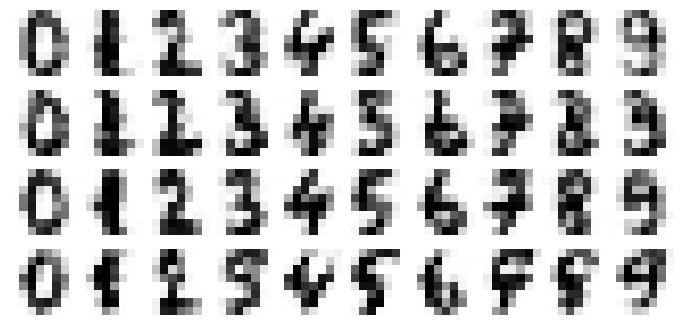

In [8]:
G0 = cg[0]["G"]
zs = torch.randn(4, 16, generator=torch.Generator().manual_seed(3))
fig, axes = plt.subplots(4, 1, figsize=(8, 3.6))
with torch.no_grad():
    for ax, z in zip(axes, zs):
        row = [G0(z[None], torch.nn.functional.one_hot(torch.tensor([d]), 10).float())[0].reshape(8, 8) for d in range(10)]
        ax.imshow(np.concatenate([r.numpy() for r in row], 1), cmap="gray_r"); ax.axis("off")
plt.show()

Each row is one noise vector, each column one label. If the noise carried the style (slant, stroke weight) and the label the class, each row would look like one writer drawing ten digits. At 8 by 8 resolution the style is limited, so look at whether the same row shares darkness and stroke thickness.

## 2. Translating the top half of a digit into the bottom half

Paired translation: for every training image we know the input (rows 0 to 3, 32 pixels) and the right output (rows 4 to 7, 32 pixels). The simplest model regresses the output from the input with a squared-error or L1 loss.
But the task has several right answers: a top half that looks like the top of a 3 or of a 9 can be followed by quite different bottoms. A regression loss responds to this by predicting an average, or a median, of the plausible answers.
The pix2pix idea is to add a conditional discriminator that sees the pair (top, bottom) and asks whether the bottom is a realistic continuation of this top, with the L1 term still tying the output to the truth.

We compare three models over three seeds, each given the noise input but, for the regression models, free to ignore it:
squared error, L1, and L1 plus the adversarial term (weight 1, L1 weight 10). The measures are on the 359 test images: the L1 error to the true bottom, how often the feature network recognizes the completed digit, how decisive the pixels are
(mean distance of a pixel from 0.5, where the real bottoms score 0.40), and how much the output changes when only the noise changes (standard deviation across four noise draws).

In [9]:
top, bottom = split_halves(Xte)
configs = {"squared error": dict(adversarial_weight=0.0, loss="l2"),
           "L1": dict(adversarial_weight=0.0, loss="l1"),
           "L1 + adversarial": dict(adversarial_weight=1.0, loss="l1")}
tr = {}
for name, kw in configs.items():
    rows, keep = [], None
    for seed in range(3):
        G = train_translator(Xtr, seed=seed, **kw)
        outs = [translate(G, top, seed=s) for s in range(4)]
        full = join_halves(top, outs[0])
        f = get_features(net, full)
        rows.append(((outs[0] - bottom).abs().mean().item(),
                     (net(full).argmax(1) == yte).float().mean().item(),
                     (outs[0] - 0.5).abs().mean().item(),
                     torch.stack(outs).std(0).mean().item(),
                     frechet_distance(f, fte)))
        if seed == 0: keep = outs
    tr[name] = (np.mean(rows, 0), keep)
print("real bottoms: decisiveness", round((bottom - 0.5).abs().mean().item(), 3), "  accuracy of the classifier on the real images", round((net(Xte).argmax(1) == yte).float().mean().item(), 3))
print()
print("model              L1 to truth   completed digit recognized   decisiveness   diversity   Frechet (full images)")
for name, (m, _) in tr.items():
    print(f"{name:17s}  {m[0]:11.3f}   {m[1]:26.3f}   {m[2]:12.3f}   {m[3]:9.3f}   {m[4]:9.1f}")

real bottoms: decisiveness 0.396   accuracy of the classifier on the real images 0.972

model              L1 to truth   completed digit recognized   decisiveness   diversity   Frechet (full images)
squared error            0.113                        0.882          0.357       0.006         2.2
L1                       0.112                        0.852          0.388       0.006         1.8
L1 + adversarial         0.127                        0.840          0.399       0.029         1.2


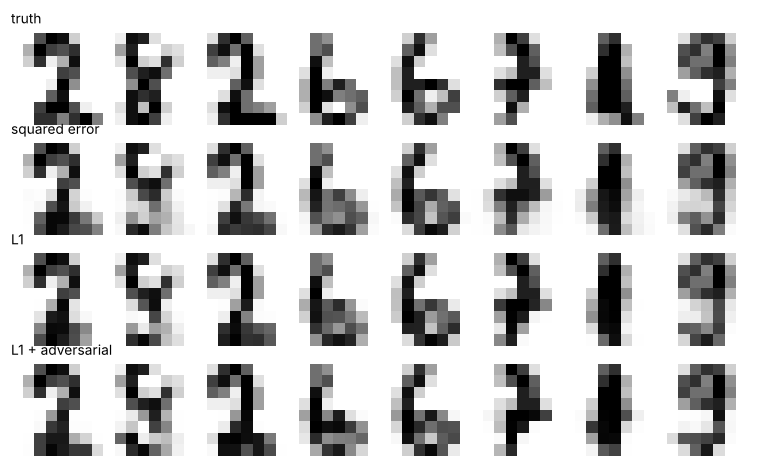

In [10]:
fig, axes = plt.subplots(4, 1, figsize=(9, 5))
idx = list(range(8))
def row(imgs): return np.concatenate([i.reshape(8, 8).numpy() for i in imgs], 1)
axes[0].imshow(row([Xte[i] for i in idx]), cmap="gray_r"); axes[0].set_title("truth", fontsize=9, loc="left")
for ax, name in zip(axes[1:], tr):
    outs = tr[name][1]
    ax.imshow(row([join_halves(top[i][None], outs[0][i][None])[0] for i in idx]), cmap="gray_r"); ax.set_title(name, fontsize=9, loc="left")
for ax in axes: ax.axis("off")
plt.show()

Read the table by column. The regression models have the lowest L1 error because minimizing it is their whole job, and they ignore the noise (diversity near zero). The adversarial model pays in L1 error and in recognizability because it commits to one plausible
bottom instead of hedging, and the noise now changes the answer. Neither number is "the" quality: they measure different things, which is the point of having several.

## 3. What a squared-error model does when two answers are right

To see the averaging directly, take the test images whose top halves are most ambiguous and compare how decisive each model's pixels are on them. The decisiveness gap between the squared-error model and the others is the
blur that a regression loss produces when it cannot pick.

In [11]:
ref = tr["squared error"][1][0]
spread = (ref - 0.5).abs().mean(1)          # low = hedging, high = decisive
order = torch.argsort(spread)[:60]          # the 60 test images where the squared-error model hedges most
for name, (_, outs) in tr.items():
    print(f"{name:17s} decisiveness on the 60 most hedged images: {(outs[0][order] - 0.5).abs().mean():.3f}")
print(f"{'real bottoms':17s} decisiveness on the same images:        {(bottom[order] - 0.5).abs().mean():.3f}")

squared error     decisiveness on the 60 most hedged images: 0.314
L1                decisiveness on the 60 most hedged images: 0.358
L1 + adversarial  decisiveness on the 60 most hedged images: 0.374
real bottoms      decisiveness on the same images:        0.388


On the images where the squared-error model hedges most, the adversarial model's pixels are far more decisive, and closer to those of real bottoms. That is the sharpness the extra loss buys, paid for with a higher error against the single recorded truth.